# 1.2 Experimentos de ingeniería de datos

Ejecución y análisis del diseño factorial definido en `1.2_ingenieria_datos.ipynb`. Se evalúa si tres transformaciones del conjunto de datos mejoran la detección:

| Factor | Niveles |
| :--- | :--- |
| Resolución | 640, 960 y 1280 px |
| Fotométrico | `base` (sin corrección), `norm` (Gray World) |
| Balanceo | `sinbal`, `bal` (copias de la clase deficitaria) |

Las 12 configuraciones se entrenan en cada uno de los 4 pliegues de validación cruzada: **48 corridas**. Cada corrida entrena con tres pliegues y se evalúa en el cuarto. El conjunto de prueba no interviene.

**Experimentos complementarios** (sección 3): sobre la configuración elegida, se entrena quitando la limpieza de etiquetas o el aumento en línea, 4 corridas cada uno, para comprobar experimentalmente su aporte.

**Protocolo común:** YOLOv11s preentrenado en COCO, SGD (`lr0 = 0.01`), lote 8, semilla 42, aumento en línea por defecto de Ultralytics y sin parada temprana. Sin balanceo se entrenan 50 épocas; con balanceo, las épocas se reducen en proporción a las copias añadidas, de modo que todas las configuraciones reciben el mismo número de iteraciones. El lote se mantiene en 8 aunque la GPU admita más, para que las corridas sean comparables.

**Entorno:** Google Colab con la misma GPU en todas las corridas (NVIDIA A100), leyendo los datos de `oe1_nube.zip`. Cada fila del registro guarda la GPU usada.

In [1]:
# --- Entorno: local, Colab o Kaggle ---
import os, sys, glob, shutil, subprocess, zipfile
from pathlib import Path

PLATAFORMA = 'colab' if 'COLAB_RELEASE_TAG' in os.environ else 'kaggle' if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ else 'local'
if PLATAFORMA == 'local':
    RAIZ = Path.cwd()
else:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.174', 'albumentations==2.0.8'], check=True)
    base = Path('/kaggle/working') if PLATAFORMA == 'kaggle' else Path('/content')
    RAIZ = base / 'maiz-yolo11' / 'oe1'
    if not (RAIZ / 'comun.py').exists():
        extraido = glob.glob('/kaggle/input/**/maiz-yolo11/oe1/comun.py', recursive=True)
        if extraido:
            shutil.copytree(Path(extraido[0]).parent.parent, RAIZ.parent)
        else:
            if PLATAFORMA == 'colab':   # el paquete está en Google Drive, que solo se lee
                from google.colab import drive
                drive.mount('/content/drive')
            origen = '/kaggle/input' if PLATAFORMA == 'kaggle' else '/content/drive/MyDrive'
            # primero la raíz; recorrer todo Drive es lento, solo si no está ahí
            paquete = glob.glob(f'{origen}/oe1_nube*.zip') or glob.glob(f'{origen}/**/oe1_nube*.zip', recursive=True)
            assert paquete, f"No se encontró oe1_nube.zip en Drive. Zips en MyDrive: {glob.glob('/content/drive/MyDrive/*.zip')}"
            zipfile.ZipFile(paquete[0]).extractall(base)
        for previo in glob.glob(str(base / 'oe1_runs*.zip')):   # sesión nueva: restaurar lo ya hecho
            zipfile.ZipFile(previo).extractall(RAIZ.parent)
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import comun as C

C.estilo()
part = json.loads((RAIZ / 'resultados' / 'particion.json').read_text())
REGISTRO = RAIZ / 'resultados' / 'experimentos.csv'
import torch
assert torch.cuda.is_available(), 'No hay GPU: en Colab, Entorno de ejecución > Cambiar tipo de entorno > GPU'
print('Plataforma:', PLATAFORMA, '| GPU:', torch.cuda.get_device_name(0))

Plataforma: local | GPU: NVIDIA GeForce RTX 3060 Laptop GPU


## 1. Corridas

Cada corrida se registra al terminar en `resultados/experimentos.csv`, con:
- **Métricas de detección:** mAP50-95 (métrica de decisión), mAP50, mAP75, precisión, recall y AP por clase.
- **Métricas de aplicación:** acierto por subtipo de defecto y error absoluto medio del conteo de granos.
- **Datos de ejecución:** épocas, minutos, VRAM máxima y GPU.

La carpeta `runs/oe1/<id>/` de cada corrida conserva los resultados de Ultralytics (curvas por época, matrices de confusión, curvas PR y argumentos) y el peso `best.pt`. Las corridas ya registradas se omiten, por lo que la ejecución puede reanudarse.

In [2]:
experimentos = C.matriz_experimentos(part)   # 12 configuraciones x 4 pliegues
decision_previa = RAIZ / 'resultados' / 'decision.json'
if decision_previa.exists():   # experimentos complementarios sobre la configuración elegida
    experimentos += C.experimentos_complementarios(part, json.loads(decision_previa.read_text()))
# La GPU local (6 GB) solo admite 640 y 960 con lote 8; 1280 va en la nube
plan = [e for e in experimentos if e['resolucion'] <= 960] if PLATAFORMA == 'local' else experimentos
hechos = set(pd.read_csv(REGISTRO).id) if REGISTRO.exists() else set()
pendientes = [e for e in plan if e['id'] not in hechos]
print(f'{len(experimentos)} corridas en total; {len(plan)} posibles en {PLATAFORMA}; {len(plan) - len(pendientes)} hechas; {len(pendientes)} pendientes')

56 corridas en total; 32 posibles en local; 32 hechas; 0 pendientes


In [3]:
import time
t0 = time.time()
for i, exp in enumerate(pendientes, 1):
    print(f"[{i}/{len(pendientes)}] {exp['id']}")
    f = C.correr(exp, part, C.DATOS, C.TRABAJO, C.RUNS, REGISTRO)   # libera la VRAM al terminar
    restante = (time.time() - t0) / i * (len(pendientes) - i) / 3600
    print(f"   mAP50-95 {f['mAP50_95']:.4f} | épocas {f['epocas']} | {f['minutos']} min | VRAM máx. {f['vram_gb']} GB "
          f"| VRAM tras liberar {torch.cuda.memory_reserved() / 1e9:.2f} GB | faltan ~{restante:.1f} h")

In [4]:
# Empaquetado de runs/ y del registro en oe1_runs.zip
if PLATAFORMA != 'local':
    destino = Path('/kaggle/working' if PLATAFORMA == 'kaggle' else '/content') / 'oe1_runs.zip'
    with zipfile.ZipFile(destino, 'w', zipfile.ZIP_DEFLATED) as z:
        for f in [REGISTRO, *C.RUNS.rglob('*')]:
            if f.is_file():   # los .pt ya están comprimidos
                z.write(f, f.relative_to(C.REPO), compress_type=zipfile.ZIP_STORED if f.suffix == '.pt' else zipfile.ZIP_DEFLATED)
    print(f'{destino} ({destino.stat().st_size / 1e6:.0f} MB)')
    if PLATAFORMA == 'colab':
        from google.colab import files
        files.download(str(destino))

## 2. Análisis y decisión

Las 48 corridas se analizan con un modelo lineal sobre el mAP50-95, con los tres factores, todas sus interacciones y el pliegue como bloque. El bloque descuenta la diferencia de dificultad entre pliegues, de modo que cada factor se evalúa comparando configuraciones dentro del mismo pliegue.

**Cómo leer las tablas:**
- **Diferencia:** cuánto cambia el mAP50-95 medio al pasar de un nivel al siguiente (por ejemplo, de 960 a 1280), promediando los demás factores. Positiva = mejora.
- **Valor p:** probabilidad de observar una diferencia así por azar, si en realidad no la hubiera. Por debajo de 0.05, la diferencia se considera **significativa** (real).
- **Influye:** si el factor, o la combinación de factores, cambia el mAP50-95 de forma significativa.
- **Rango probable (solo en el gráfico):** intervalo de confianza del 95 %, el rango en el que probablemente está la diferencia real. Si la barra cruza el 0, no se puede descartar que no haya diferencia.

**Reglas de decisión:**
- **Resolución:** se parte de 640 y se sube al nivel siguiente solo si mejora el mAP50-95 en al menos +0.010 y la mejora es significativa. El umbral compensa el mayor costo de entrenamiento e inferencia.
- **Normalización fotométrica y balanceo:** se adoptan solo si mejoran de forma significativa.
- En los demás casos se mantiene la opción más simple.

La configuración resultante se usa en la Actividad 1.3 para construir el dataset final.

### 2.1. Completitud del diseño

Cada combinación de configuración y pliegue debe tener exactamente una corrida; si falta alguna, el análisis no es definitivo.

In [5]:
todas = pd.read_csv(REGISTRO).drop_duplicates('id', keep='last')
if 'complementario' not in todas:
    todas['complementario'] = np.nan
df = todas[todas['complementario'].isna()]   # diseño factorial; los complementarios van en la sección 3
completitud = pd.crosstab([df.resolucion, df.fotometrico, df.balanceo], df.pliegue)
COMPLETO = completitud.shape == (len(C.configuraciones()), part['k']) and (completitud.values == 1).all()
print('Diseño completo' if COMPLETO else 'FALTAN corridas: el análisis no es definitivo.')
completitud

Diseño completo


pliegue                          0  1  2  3
resolucion fotometrico balanceo            
640        base        bal       1  1  1  1
                       sinbal    1  1  1  1
           norm        bal       1  1  1  1
                       sinbal    1  1  1  1
960        base        bal       1  1  1  1
                       sinbal    1  1  1  1
           norm        bal       1  1  1  1
                       sinbal    1  1  1  1
1280       base        bal       1  1  1  1
                       sinbal    1  1  1  1
           norm        bal       1  1  1  1
                       sinbal    1  1  1  1

### 2.2. ¿Qué factores influyen?

Para cada factor y cada combinación de factores (interacción), si cambia el mAP50-95 de forma significativa. Una interacción significativa indicaría que el efecto de un factor depende del nivel de otro; en ese caso, los factores no podrían decidirse por separado.

In [6]:
C.anova(df, 'mAP50_95').round(4)

,factor,valor p,influye
0,resolucion,0.0000,Sí
1,fotometrico,0.5595,No
2,balanceo,0.3724,No
3,resolucion x fotometrico,0.8101,No
4,resolucion x balanceo,0.1733,No
5,fotometrico x balanceo,0.9254,No
6,resolucion x fotometrico x balanceo,0.4962,No


### 2.3. Diferencias entre niveles y decisión

Diferencia de mAP50-95 en cada paso entre niveles, con su valor p, y decisión resultante según las reglas.

In [7]:
tabla = C.analizar(df, 'mAP50_95')
decision = C.decidir(tabla)
display(tabla.drop(columns=['mínimo probable', 'máximo probable']).round(4))   # el rango va en el gráfico
pd.DataFrame({f: {'elegido': v['elegido']} for f, v in decision.items()}).T

,comparación,diferencia,valor p,significativo
0,resolucion: 960 - 640,0.0192,0.0000,Sí
1,resolucion: 1280 - 960,0.0078,0.0527,No
2,fotometrico: norm - base,0.0019,0.5595,No
3,balanceo: bal - sinbal,-0.0029,0.3724,No


,elegido
resolucion,960
fotometrico,base
balanceo,sinbal


### 2.4. Gráfico de diferencias

Cada punto es la diferencia media y la barra, su rango probable (IC 95 %). Una barra que no cruza el 0 indica una diferencia significativa.

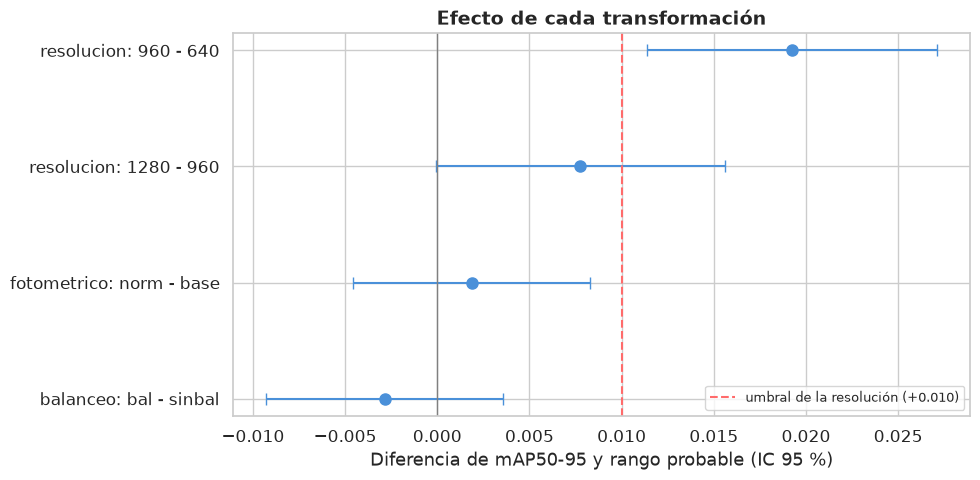

In [8]:
SALIDA = RAIZ / 'salida' / '1.2_experimentos'
t = tabla.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(t['diferencia'], range(len(t)), xerr=[t['diferencia'] - t['mínimo probable'], t['máximo probable'] - t['diferencia']],
            fmt='o', color='#4A90D9', capsize=4, markersize=8)
ax.axvline(0, color='grey', lw=1); ax.axvline(0.010, color='#FF6B6B', ls='--', label='umbral de la resolución (+0.010)')
ax.set_yticks(range(len(t))); ax.set_yticklabels(t['comparación']); ax.set_xlabel('Diferencia de mAP50-95 y rango probable (IC 95 %)')
ax.set_title('Efecto de cada transformación'); ax.legend(fontsize=9)
C.guardar(SALIDA, 'efectos_transformaciones.png')

### 2.5. Medias por configuración

Promedio de los 4 pliegues. El tiempo (`minutos`) muestra el costo de cada configuración. El gráfico muestra cómo cambia el mAP50-95 con la resolución en cada combinación de los otros dos factores: líneas paralelas indican que no hay interacción.

mAP50_95   mAP50  precision  recall  \
resolucion fotometrico balanceo                                        
1280       base        bal         0.7483  0.9804     0.9341  0.9454   
           norm        bal         0.7454  0.9696     0.8918  0.9384   
                       sinbal      0.7440  0.9733     0.8952  0.9355   
           base        sinbal      0.7410  0.9798     0.9364  0.9350   
960        norm        sinbal      0.7400  0.9783     0.9108  0.9411   
           base        bal         0.7368  0.9746     0.9245  0.9217   
                       sinbal      0.7363  0.9742     0.9099  0.9401   
           norm        bal         0.7345  0.9703     0.9076  0.9287   
640        base        sinbal      0.7231  0.9701     0.8966  0.9254   
           norm        sinbal      0.7228  0.9689     0.9090  0.9077   
                       bal         0.7173  0.9548     0.8779  0.9189   
           base        bal         0.7075  0.9593     0.8919  0.9046   

                                 mae_conteo  minutos  
resolucion fotometrico balanceo                       
1280       base        bal           0.3379    4.875  
           norm        bal           0.3362    4.850  
                       sinbal        0.3574    4.900  
           base        sinbal        0.3285    4.925  
960        norm        sinbal        0.3606    4.050  
           base        bal           0.4441    4.000  
                       sinbal        0.3766    4.125  
           norm        bal           0.5147    4.000  
640        base        sinbal        0.7789    3.600  
           norm        sinbal        0.7410    3.525  
                       bal           0.6750    3.525  
           base        bal           0.7009    3.500

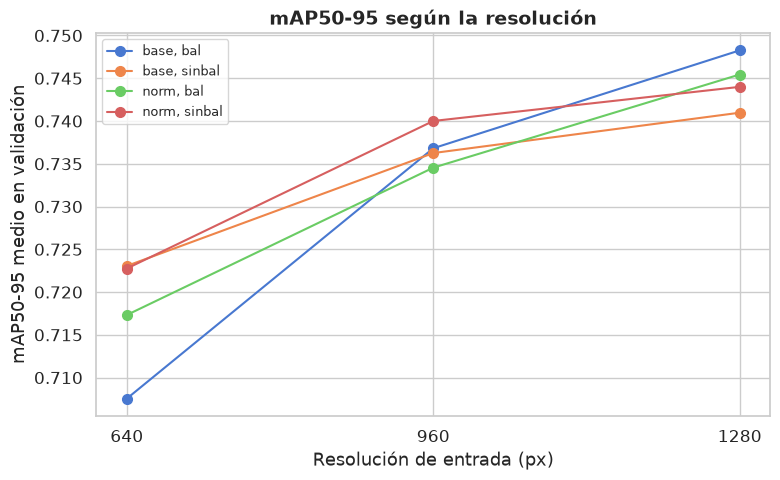

In [9]:
medias = df.groupby(['resolucion', 'fotometrico', 'balanceo'])[['mAP50_95', 'mAP50', 'precision', 'recall', 'mae_conteo', 'minutos']].mean()
display(medias.round(4).sort_values('mAP50_95', ascending=False))
fig, ax = plt.subplots(figsize=(8, 5))
for (foto, bal), g in df.groupby(['fotometrico', 'balanceo']):
    m = g.groupby('resolucion').mAP50_95.mean()
    ax.plot(m.index.astype(str), m.values, 'o-', markersize=7, label=f'{foto}, {bal}')
ax.set_xlabel('Resolución de entrada (px)'); ax.set_ylabel('mAP50-95 medio en validación')
ax.set_title('mAP50-95 según la resolución'); ax.legend(fontsize=9)
C.guardar(SALIDA, 'medias_por_resolucion.png')

### 2.6. Efecto sobre cada subtipo de defecto

Diferencia del acierto por subtipo entre niveles consecutivos de cada factor. Indica si una transformación favorece a algunos defectos a costa de otros.

In [10]:
subtipos = [f'acierto_{C.CLASES[i]}' for i in C.SUBTIPOS]
filas = []
for f, niveles in C.FACTORES.items():
    m = df.groupby(f)[subtipos].mean()
    niveles = [n for n in niveles if n in m.index]   # presentes
    for bajo, alto in zip(niveles, niveles[1:]):
        filas.append((m.loc[alto] - m.loc[bajo]).rename(f'{f}: {alto} - {bajo}'))
pd.DataFrame(filas).round(3)

,acierto_Broken,acierto_Damage,acierto_Fungus,acierto_Healthy,acierto_Immature,acierto_Shriveled,acierto_Weeveled
resolucion: 960 - 640,0.023,0.001,0.011,0.015,0.074,-0.005,0.044
resolucion: 1280 - 960,0.015,0.011,-0.023,-0.011,0.032,0.001,0.057
fotometrico: norm - base,-0.005,-0.002,-0.015,0.007,-0.024,-0.005,-0.046
balanceo: bal - sinbal,0.009,0.000,0.011,-0.015,-0.042,0.004,-0.020


### 2.7. Desviación declarada: 1280

La regla conduce a 960: el paso de 640 a 960 cumple el umbral, pero el de 960 a 1280 no. Se adopta **1280 como desviación declarada de la regla**, por cuatro motivos:

1. **Es la resolución con la media más alta** y supera a 960 en la mayoría de las comparaciones pareadas (misma configuración y pliegue), aunque la diferencia no alcanza la significación al 5 % (tabla siguiente).
2. **El mAP50-95 crece con la resolución**, de forma coherente con el EDA: el porcentaje de granos de menos de 24 px es del 47.5 % a 640, del 14.6 % a 960 y del 4.5 % a 1280.
3. **Las métricas de aplicación mejoran en la misma dirección:** el error de conteo y el acierto de los subtipos más difíciles (`Weeveled` e `Immature`).
4. **El costo adicional es asumible:** ~20 % más de tiempo por corrida. Requiere unos 12 GB de VRAM con lote 8, así que se entrena en la nube.

La evidencia a favor de 1280 frente a 960 es moderada, y así se declara. El conjunto de prueba no interviene.

In [11]:
r = tabla.set_index('comparación').loc['resolucion: 1280 - 960']
piv = df.pivot_table(index=['fotometrico', 'balanceo', 'pliegue'], columns='resolucion', values='mAP50_95')
print(f"1280 supera a 960 en {(piv[1280] > piv[960]).sum()} de {len(piv)} comparaciones pareadas")
respaldo = []
for m in ['mAP50_95', 'mae_conteo', 'acierto_Weeveled', 'acierto_Immature']:
    t = C.analizar(df, m).set_index('comparación').loc['resolucion: 1280 - 960']
    respaldo.append({'métrica': m, 'diferencia 1280 - 960': t['diferencia'], 'valor p': t['valor p'], 'significativo': t['significativo']})
display(pd.DataFrame(respaldo).round(4))

if decision['resolucion']['elegido'] == 960 and r['diferencia'] > 0:
    decision['resolucion'].update({'elegido': 1280, 'regla': 960,
        'nota': f"Desviación declarada: la regla da 960; se adopta 1280, la de mayor media ({r['diferencia']:+.4f} frente a 960, "
                f"p = {r['valor p']:.3f}; {(piv[1280] > piv[960]).sum()}/{len(piv)} comparaciones pareadas a favor), por la tendencia "
                f"creciente con la resolución, coherente con el EDA, y por su costo asumible."})
pd.DataFrame({f: {'elegido': v['elegido']} for f, v in decision.items()}).T

1280 supera a 960 en 12 de 16 comparaciones pareadas


,métrica,diferencia 1280 - 960,valor p,significativo
0,mAP50_95,0.0078,0.0527,No
1,mae_conteo,-0.0840,0.0825,No
2,acierto_Weeveled,0.0570,0.3365,No
3,acierto_Immature,0.0325,0.4494,No


,elegido
resolucion,1280
fotometrico,base
balanceo,sinbal


### 2.8. Registro de la decisión

Si el diseño está completo, la decisión se guarda en `resultados/decision.json` para la Actividad 1.3.

In [12]:
if COMPLETO:
    (RAIZ / 'resultados' / 'decision.json').write_text(json.dumps(decision, indent=1, ensure_ascii=False, default=float))
    print('Decisión guardada en resultados/decision.json')

Decisión guardada en resultados/decision.json


## 3. Experimentos complementarios: limpieza y aumento

La limpieza de etiquetas y el aumento en línea se aplican sin pasar por el diseño factorial. Para comprobar su aporte, se entrena la configuración elegida **quitando cada técnica** y se compara, pliegue a pliegue, con las corridas del diseño de esa misma configuración, que sí la incluyen:

- **Limpieza:** entrenamiento con las etiquetas originales (v0) en lugar de las corregidas. La validación usa siempre las etiquetas corregidas.
- **Aumento:** entrenamiento sin ningún aumento de Ultralytics (mosaico, volteo, escala, traslación, HSV y sus transformaciones de Albumentations).

La **diferencia** es *con la técnica − sin ella*: positiva = la técnica mejora (en el MAE de conteo, negativa = mejora). **Pliegues a favor** cuenta en cuántos de los 4 pliegues mejora. El valor p sale de una prueba t pareada por pliegue; con 4 pliegues tiene poca potencia, así que una diferencia consistente en los 4 pliegues también es evidencia relevante.

con la técnica  \
técnica                                         métrica                      
Limpieza de etiquetas (corregidas − originales) mAP50_95            0.7410   
                                                mAP50               0.9798   
                                                precision           0.9364   
                                                recall              0.9350   
                                                mae_conteo          0.3285   
Aumento en línea (con − sin)                    mAP50_95            0.7410   
                                                mAP50               0.9798   
                                                precision           0.9364   
                                                recall              0.9350   
                                                mae_conteo          0.3285   

                                                            sin la técnica  \
técnica                                         métrica                      
Limpieza de etiquetas (corregidas − originales) mAP50_95            0.7195   
                                                mAP50               0.9509   
                                                precision           0.8974   
                                                recall              0.9232   
                                                mae_conteo          0.3065   
Aumento en línea (con − sin)                    mAP50_95            0.7001   
                                                mAP50               0.9530   
                                                precision           0.8803   
                                                recall              0.9108   
                                                mae_conteo          0.4583   

                                                            diferencia  \
técnica                                         métrica                  
Limpieza de etiquetas (corregidas − originales) mAP50_95        0.0214   
                                                mAP50           0.0289   
                                                precision       0.0390   
                                                recall          0.0118   
                                                mae_conteo      0.0219   
Aumento en línea (con − sin)                    mAP50_95        0.0408   
                                                mAP50           0.0268   
                                                precision       0.0562   
                                                recall          0.0242   
                                                mae_conteo     -0.1298   

                                                           pliegues a favor  \
técnica                                         métrica                       
Limpieza de etiquetas (corregidas − originales) mAP50_95                4/4   
                                                mAP50                   4/4   
                                                precision               3/4   
                                                recall                  3/4   
                                                mae_conteo              2/4   
Aumento en línea (con − sin)                    mAP50_95                4/4   
                                                mAP50                   4/4   
                                                precision               3/4   
                                                recall                  3/4   
                                                mae_conteo              4/4   

                                                            valor p  \
técnica                                         métrica               
Limpieza de etiquetas (corregidas − originales) mAP50_95     0.0756   
                                                mAP50        0.0388   
                                                precision    0.3

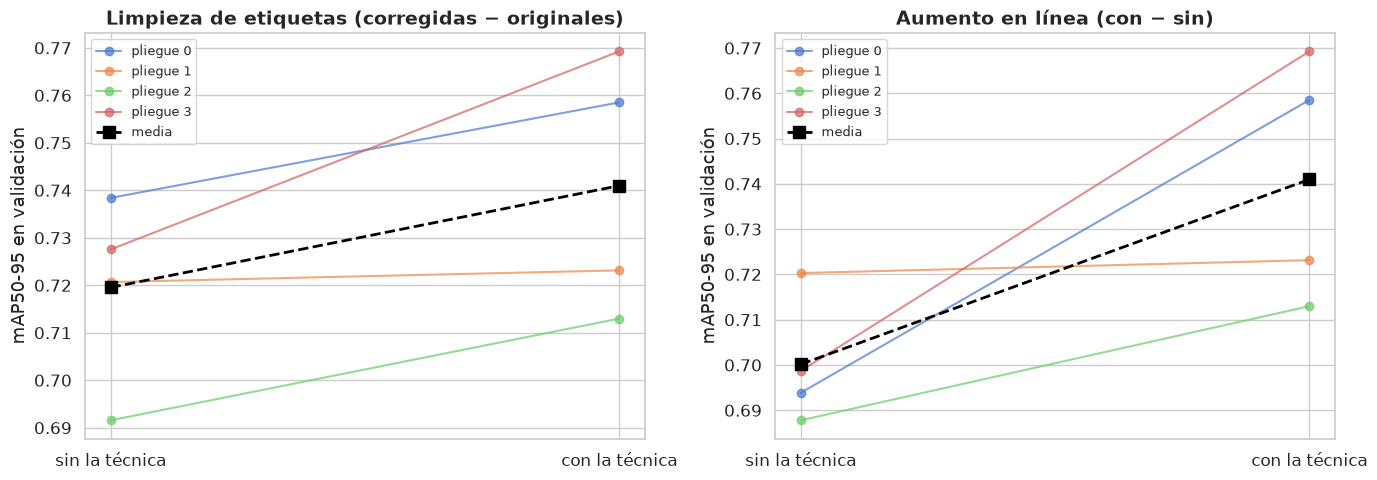

In [13]:
from scipy import stats
cfg = {f: decision[f]['elegido'] for f in C.FACTORES}
con = df[(df.resolucion == cfg['resolucion']) & (df.fotometrico == cfg['fotometrico']) & (df.balanceo == cfg['balanceo'])].set_index('pliegue')
metricas = {'mAP50_95': 1, 'mAP50': 1, 'precision': 1, 'recall': 1, 'mae_conteo': -1}   # -1: menor es mejor
filas, comparadas = [], {}
for comp, nombre in C.COMPLEMENTARIOS.items():
    sin = todas[todas['complementario'] == comp].set_index('pliegue')
    if len(sin) < part['k']:
        print(f'Faltan corridas de {comp}: {len(sin)} de {part["k"]}.'); continue
    comparadas[nombre] = sin
    for m, signo in metricas.items():
        d = con[m] - sin.loc[con.index, m]
        p = stats.ttest_rel(con[m], sin.loc[con.index, m]).pvalue
        filas.append({'técnica': nombre, 'métrica': m, 'con la técnica': con[m].mean(), 'sin la técnica': sin[m].mean(),
                      'diferencia': d.mean(), 'pliegues a favor': f'{(signo * d > 0).sum()}/{len(d)}',
                      'valor p': p, 'significativo': 'Sí' if p < 0.05 else 'No'})
if filas:
    display(pd.DataFrame(filas).set_index(['técnica', 'métrica']).round(4))
    fig, axes = plt.subplots(1, len(comparadas), figsize=(7 * len(comparadas), 5), squeeze=False)
    for ax, (nombre, sin) in zip(axes[0], comparadas.items()):
        for k in con.index:
            ax.plot(['sin la técnica', 'con la técnica'], [sin.loc[k, 'mAP50_95'], con.loc[k, 'mAP50_95']], 'o-', alpha=0.7, label=f'pliegue {k}')
        ax.plot(['sin la técnica', 'con la técnica'], [sin.mAP50_95.mean(), con.mAP50_95.mean()], 's--', color='black', lw=2, markersize=8, label='media')
        ax.set_title(nombre); ax.set_ylabel('mAP50-95 en validación'); ax.legend(fontsize=9)
    C.guardar(SALIDA, 'experimentos_complementarios.png')